In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Accuracy Score: 96.6666666667%

Classification Report:
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.89      0.94         9
 Iris-virginica       0.92      1.00      0.96        11

       accuracy                           0.97        30
      macro avg       0.97      0.96      0.97        30
   weighted avg       0.97      0.97      0.97        30



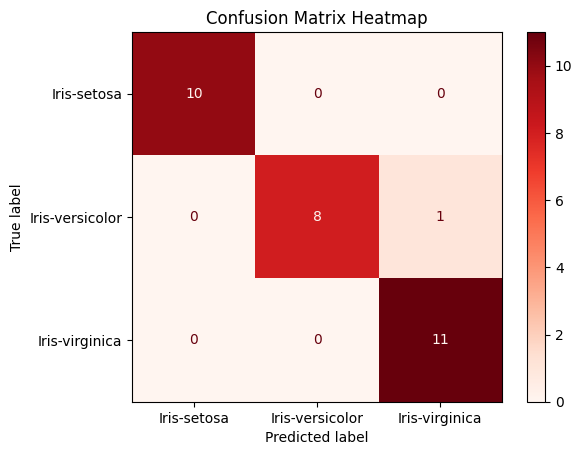

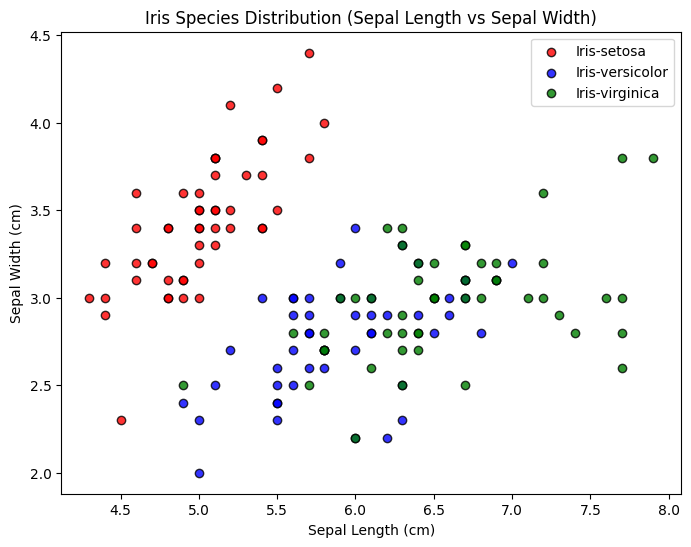

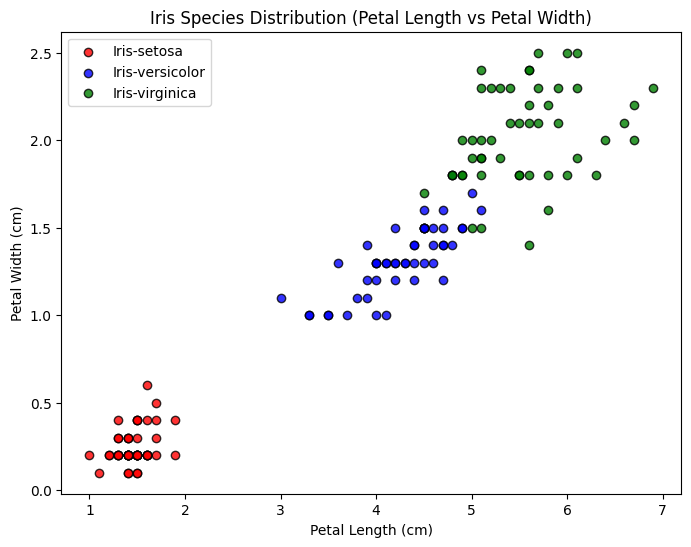

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Load the Iris dataset directly from scikit-learn (No internet or CSV file needed)
iris = load_iris()
df = pd.DataFrame(iris.data, columns=['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm'])

# Map target numbers back to original string species names (e.g., 'Iris-setosa')
df['Species'] = pd.Series(iris.target).map(
    {0: 'Iris-setosa', 1: 'Iris-versicolor', 2: 'Iris-virginica'}
)

# Define features and target
X = df[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]
y = df['Species']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Support Vector Machine model
svm_model = SVC(kernel='linear', C=1.0, random_state=42)
svm_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = svm_model.predict(X_test_scaled)

# Evaluate model performance
print(f'Accuracy Score: {accuracy_score(y_test, y_pred) * 100:.10f}%')
print('\nClassification Report:\n', classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=svm_model.classes_
)
disp.plot(cmap='Reds', values_format='d')
plt.title('Confusion Matrix Heatmap')
plt.show()

# Visualizations with proper Legends
colors = {
    'Iris-setosa': 'red',
    'Iris-versicolor': 'blue',
    'Iris-virginica': 'green',
}

# 1. Sepal Length vs Sepal Width
plt.figure(figsize=(8, 6))
for species, color in colors.items():
  subset = df[df['Species'] == species]
  plt.scatter(
      subset['SepalLengthCm'],
      subset['SepalWidthCm'],
      c=color,
      label=species,
      alpha=0.8,
      edgecolors='k',
  )
plt.title('Iris Species Distribution (Sepal Length vs Sepal Width)')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.legend()
plt.show()

# 2. Petal Length vs Petal Width
plt.figure(figsize=(8, 6))
for species, color in colors.items():
  subset = df[df['Species'] == species]
  plt.scatter(
      subset['PetalLengthCm'],
      subset['PetalWidthCm'],
      c=color,
      label=species,
      alpha=0.8,
      edgecolors='k',
  )
plt.title('Iris Species Distribution (Petal Length vs Petal Width)')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.legend()
plt.show()